<a href="https://colab.research.google.com/github/bookwork123/MachineLearning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

**Task 1: Dataset Loading and Dimensionality Inspection. Load the Olivetti Faces dataset using `sklearn.datasets.fetch_olivetti_faces`. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.**

The first code block uses Scikit-Learn's fetch_olivetti_faces to load the dataset. X holds the flattened images and y holds the subject ID for each image. The pixel values are already scaled between 0 and 1.

The second block prints the total number of samples, the number of unique subjects, and the number of features. Each 64 x 64 grayscale image is flattened into a single vector of 4,096 pixels.

In the third block, I define a plot_faces function that reshapes each vector back into a 64 x 64 image and displays it with its label. I then plot the first image of the first 20 subjects in a 4 x 5 grid.

In [ ]:
olivetti = fetch_olivetti_faces()
X = olivetti.data
y = olivetti.target

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


In [ ]:
print(f"Total number of samples: {X.shape[0]}")
print(f"Unique target subjects: {len(np.unique(y))}")
print(f"Feature dimensions: {X.shape[1]} (64 x 64 pixels)")

Total number of samples: 400
Unique target subjects: 40
Feature dimensions: 4096 (64 x 64 pixels)


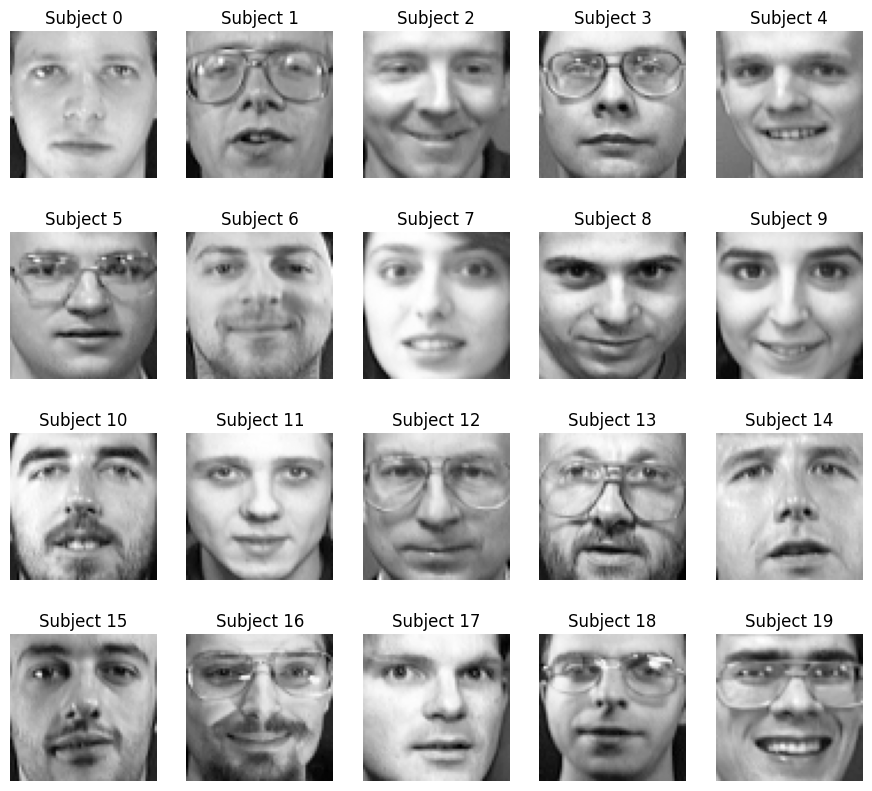

In [ ]:
def plot_faces(faces, labels, n_cols=5):
    faces = faces.reshape(-1, 64, 64)
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * 2.2, n_rows * 2.5))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray")
        plt.axis("off")
        plt.title(label)
    plt.show()

sample_faces = X[::10][:20]
sample_labels = [f"Subject {label}" for label in y[::10][:20]]

plot_faces(sample_faces, sample_labels)

**Task 2: Cumulative Explained Variance & Elbow Plot. Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.**

The first code block fits a full PCA model on the dataset. Since we have 400 samples and 4,096 features, the maximum number of components is min(400, 4096) = 400. I then get the explained variance ratio of each component and the cumulative sum of those ratios.

In the second block, I find the number of components needed to preserve 90%, 95%, and 99% of the variance. np.argmax returns the first index where the cumulative variance passes each threshold, so I add 1 to turn it into a component count.

In the third block, I plot the individual explained variance ratio on the left and the cumulative explained variance (elbow plot) on the right, with dashed lines marking each threshold.

In [ ]:
# Initialize PCA and fit on the feature matrix
pca = PCA(n_components=None)
pca.fit(X)

# Explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print(f"Number of principal components computed: {len(explained_variance_ratio)}")

Number of principal components computed: 400


In [ ]:
# Determine number of components needed for 90%, 95%, and 99% variance
n_components_90 = np.argmax(cumulative_variance_ratio >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
n_components_99 = np.argmax(cumulative_variance_ratio >= 0.99) + 1

print(f"Number of components required for 90% variance: {n_components_90}")
print(f"Number of components required for 95% variance: {n_components_95}")
print(f"Number of components required for 99% variance: {n_components_99}")

Number of components required for 90% variance: 66
Number of components required for 95% variance: 123
Number of components required for 99% variance: 260


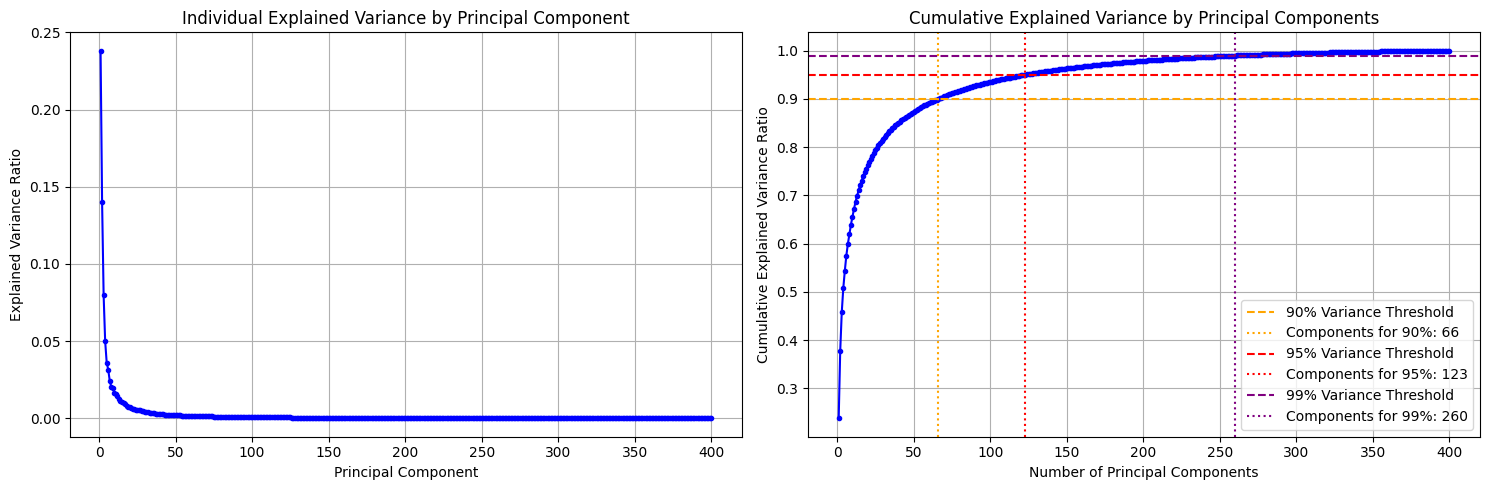

In [ ]:
components = np.arange(1, len(explained_variance_ratio) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(components, explained_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)
axes[0].set_title('Individual Explained Variance by Principal Component')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].grid(True)

# Plotting the Cumulative Explained Variance (Elbow Method)
axes[1].plot(components, cumulative_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)
axes[1].axhline(y=0.90, color='orange', linestyle='--', label='90% Variance Threshold')
axes[1].axvline(x=n_components_90, color='orange', linestyle=':', label=f'Components for 90%: {n_components_90}')
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
axes[1].axvline(x=n_components_95, color='r', linestyle=':', label=f'Components for 95%: {n_components_95}')
axes[1].axhline(y=0.99, color='purple', linestyle='--', label='99% Variance Threshold')
axes[1].axvline(x=n_components_99, color='purple', linestyle=':', label=f'Components for 99%: {n_components_99}')

axes[1].set_title('Cumulative Explained Variance by Principal Components')
axes[1].set_xlabel('Number of Principal Components')
axes[1].set_ylabel('Cumulative Explained Variance Ratio')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Task 3: Image Compression and Reconstruction Analysis. Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.**

In the first code block, I select 5 faces from 5 different subjects and define a reconstruction_errors function. It projects images into the reduced PCA space, reconstructs them back into the original 4,096-dimensional pixel space with inverse_transform, and returns the MSE for each image.

In the second block, I loop through each value of k, fit a PCA model with k components, and reconstruct all the images. I save the reconstructions of the 5 selected faces and their average MSE.

The third block reuses the plot_faces function from Task 1 to plot a grid with one row per face. The first column is the original image and the following columns are its reconstructions for each value of k.

In the fourth block, I plot the MSE as a function of k to show how the reconstruction error drops as more components are kept.

In [ ]:
sample_indices = [0, 100, 200, 300, 390]
component_levels = [10, 50, 100, 200, 300]

def reconstruction_errors(pca, X):
    X_pca = pca.transform(X)
    X_reconstructed = pca.inverse_transform(X_pca)
    mse = np.square(X_reconstructed - X).mean(axis=-1)
    return mse

In [ ]:
reconstructions = {}
mse_values = []

for n_comp in component_levels:
    pca_temp = PCA(n_components=n_comp)
    X_red_temp = pca_temp.fit_transform(X)
    X_rec_temp = pca_temp.inverse_transform(X_red_temp)

    reconstructions[n_comp] = X_rec_temp[sample_indices]
    mse = reconstruction_errors(pca_temp, X[sample_indices]).mean()
    mse_values.append(mse)
    print(f"k = {n_comp:<4} MSE: {mse:.6f}")

k = 10   MSE: 0.004735
k = 50   MSE: 0.002060
k = 100  MSE: 0.001064
k = 200  MSE: 0.000426
k = 300  MSE: 0.000138


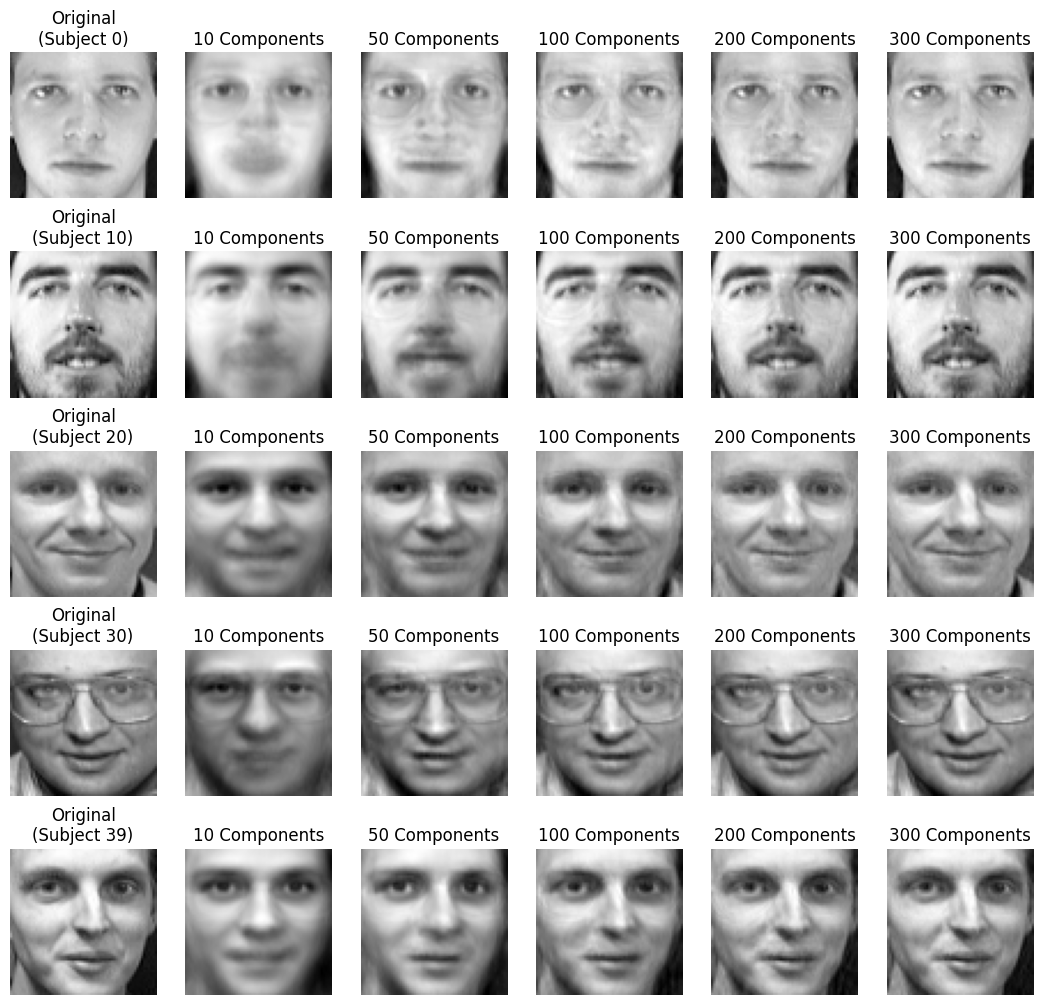

In [ ]:
# Compare reconstructions across different numbers of principal components
grid_faces = np.stack([X[sample_indices]] + [reconstructions[n_comp] for n_comp in component_levels], axis=1)
grid_labels = np.array([[f"Original\n(Subject {y[idx]})"] + [f"{n_comp} Components" for n_comp in component_levels]
                        for idx in sample_indices])

plot_faces(np.clip(grid_faces, 0, 1), grid_labels.ravel(), n_cols=6)

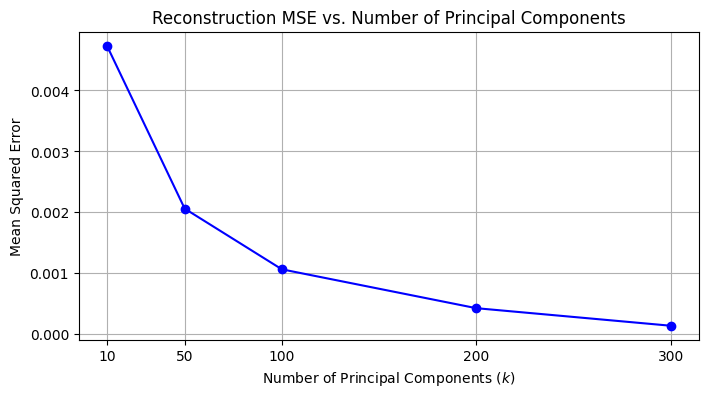

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(component_levels, mse_values, "bo-")
plt.title('Reconstruction MSE vs. Number of Principal Components')
plt.xlabel("Number of Principal Components ($k$)")
plt.ylabel("Mean Squared Error")
plt.xticks(component_levels)
plt.grid()
plt.show()

**Task 4: Visualization of "Eigenfaces". Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5 plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.**

The code block below takes the first 15 principal components from the full PCA model fitted in Task 2. Each component is a vector in the original 4,096-dimensional pixel space, so I reshape it back into a 64 x 64 image. These are the "eigenfaces": the basis images that PCA combines to rebuild any face in the dataset.

I reuse the plot_faces function from Task 1, which reshapes each component into a 64 x 64 image and lays them out in a 3 x 5 grid. Each plot is titled with the percentage of total variance its component explains.

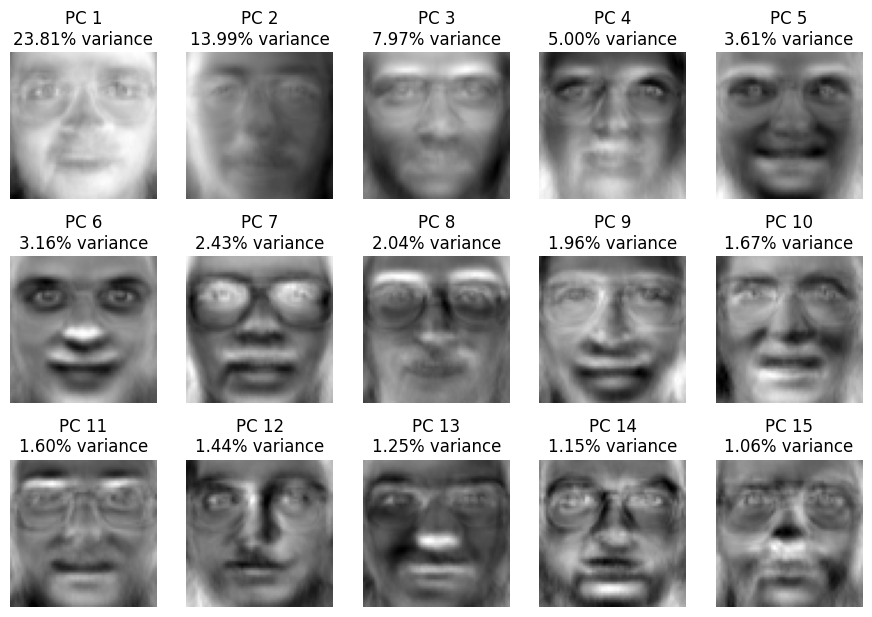

In [ ]:
# Visualize the first 15 principal components as images (Eigenfaces)
eigenfaces = pca.components_[:15]
eigenface_labels = [f"PC {i + 1}\n{explained_variance_ratio[i] * 100:.2f}% variance" for i in range(15)]

plot_faces(eigenfaces, eigenface_labels)

**Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model). Perform a stratified train/test split (80/20). Train a `LogisticRegression` classifier on: (1) the raw 4,096-dimensional feature vectors, and (2) the PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set. Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).**

In the first code block, I make a stratified 80/20 train/test split so every subject has the same number of images in each set (8 in training, 2 in testing), then print the shape of each set.

In the second block, I train a Logistic Regression classifier on the raw 4,096 pixel features and record its test accuracy and training time.

In the third block, I fit a PCA model with n_components=0.95 on the training set only, so no information from the test set leaks into the model. PCA picks the smallest number of components that keeps 95% of the training variance. I then transform both sets and train a second Logistic Regression on the reduced features. The training time includes fitting the PCA.

The fourth block plots accuracy (left axis) and training time (right axis) side by side for both models.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (320, 4096)
Testing set shape: (80, 4096)


In [ ]:
# 1. Train classifier on Raw Features (4,096 dimensions)
print("Training classifier on raw features...")
start_time = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Features Accuracy: {raw_accuracy:.4f} (Training time: {raw_time:.2f}s)")

Training classifier on raw features...
Raw Features Accuracy: 0.9625 (Training time: 34.26s)


In [ ]:
# 2. Train classifier on PCA-reduced Features (95% variance)
print("Training classifier on PCA-reduced features (95% variance)...")
start_time = time.time()

# Fit PCA on training data only to avoid data leakage
pca_clf = PCA(n_components=0.95)
X_train_reduced = pca_clf.fit_transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000, random_state=42)
clf_pca.fit(X_train_reduced, y_train)
pca_time = time.time() - start_time

y_pred_pca = clf_pca.predict(X_test_reduced)
pca_accuracy = accuracy_score(y_test, y_pred_pca)

n_pca = pca_clf.n_components_
print(f"Components kept for 95% variance (training set): {n_pca}")
print(f"PCA-Reduced Features Accuracy: {pca_accuracy:.4f} (Training time: {pca_time:.2f}s)")

Training classifier on PCA-reduced features (95% variance)...
Components kept for 95% variance (training set): 111
PCA-Reduced Features Accuracy: 0.9625 (Training time: 0.66s)


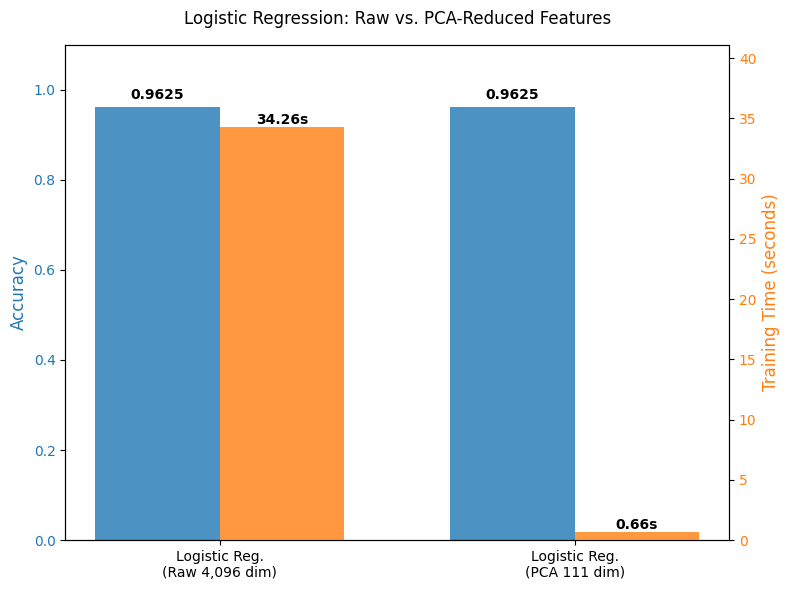

In [ ]:
models = [
    'Logistic Reg.\n(Raw 4,096 dim)',
    f'Logistic Reg.\n(PCA {n_pca} dim)'
]

accuracies = [raw_accuracy, pca_accuracy]
train_times = [raw_time, pca_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Instantiate secondary axis for training time
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(train_times) * 1.2)

# Annotate values on top of each bar
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, f"{yval:.4f}",
             ha="center", va="bottom", fontsize=10, fontweight="bold")
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, yval, f"{yval:.2f}s",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Logistic Regression: Raw vs. PCA-Reduced Features', fontsize=12, pad=15)
fig.tight_layout()
plt.show()

**Task 6: Non-Linear Classification (Kernel SVM). Train a `SVC` with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.**

The first code block trains an SVC with an RBF kernel on the same PCA-reduced features from Task 5 and records its training time and test accuracy.

In the second block, I display the confusion matrices of the RBF SVM and the linear baseline (Logistic Regression on the PCA-reduced features) side by side. With 40 subjects, each matrix is 40 x 40, so the cell values are hidden and the colors show the counts. A correct prediction lands on the diagonal, so any off-diagonal square is a face assigned to the wrong subject.

In [ ]:
print("Training SVC (RBF kernel) on PCA-reduced features...")
start_time = time.time()
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_reduced, y_train)
svm_time = time.time() - start_time

y_pred_svm = svm_rbf.predict(X_test_reduced)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"SVC (RBF) Accuracy: {svm_accuracy:.4f} (Training time: {svm_time:.2f}s)")

Training SVC (RBF kernel) on PCA-reduced features...
SVC (RBF) Accuracy: 0.9375 (Training time: 0.03s)


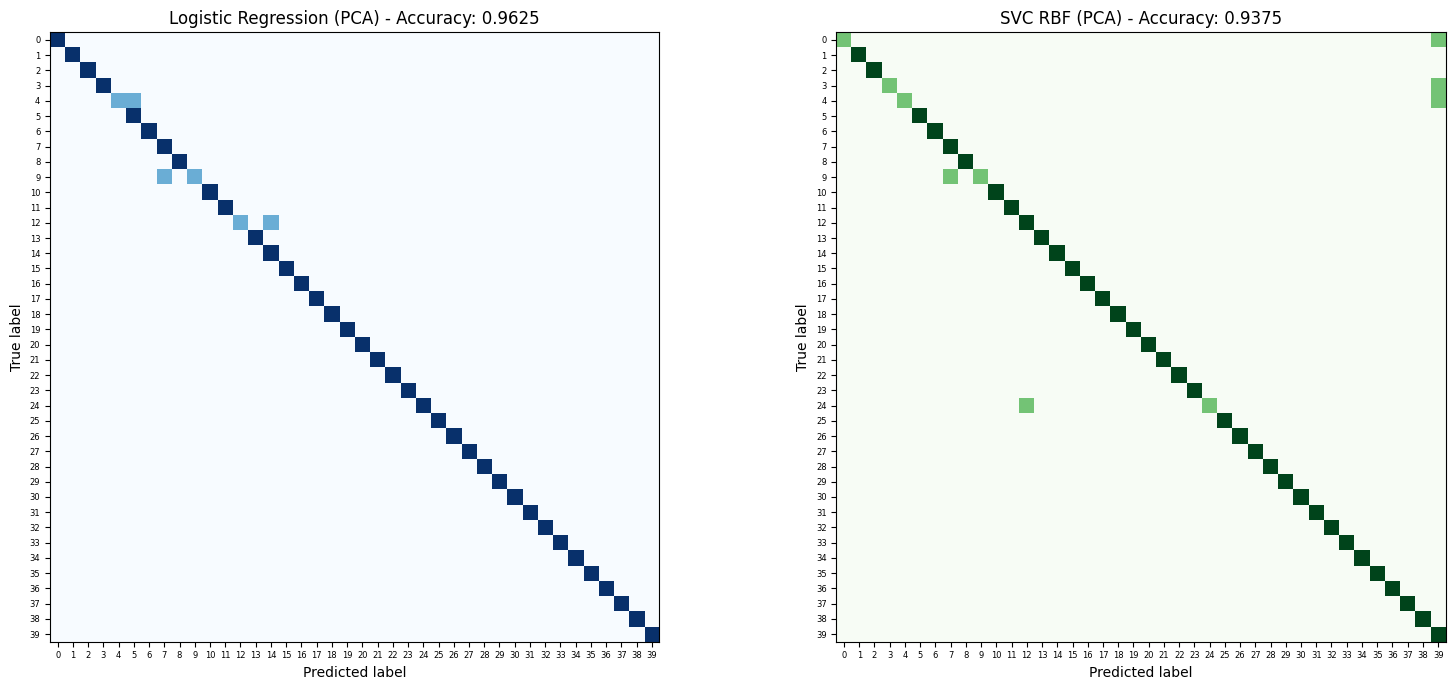

In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_pca)
cm_svm = confusion_matrix(y_test, y_pred_svm)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay(cm_lr).plot(ax=axes[0], cmap='Blues', colorbar=False, include_values=False)
axes[0].set_title(f'Logistic Regression (PCA) - Accuracy: {pca_accuracy:.4f}')
ConfusionMatrixDisplay(cm_svm).plot(ax=axes[1], cmap='Greens', colorbar=False, include_values=False)
axes[1].set_title(f'SVC RBF (PCA) - Accuracy: {svm_accuracy:.4f}')
for ax in axes:
    ax.tick_params(axis='both', labelsize=6)
plt.tight_layout()
plt.show()

**Task 7: Ensemble Classification on PCA Features. Construct a `VotingClassifier` (soft voting) combining a Polynomial Kernel SVM (`degree=2`), an RBF Kernel SVM, and a `RandomForestClassifier` (`n_estimators=100`). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.**

In the first code block, I create the three base models: a Polynomial Kernel SVM with degree=2, an RBF Kernel SVM, and a Random Forest with 100 trees. Both SVMs use probability=True so they can take part in soft voting. I combine them in a soft Voting Classifier (which averages the predicted probabilities), train it on the PCA-reduced features, and record its training time and test accuracy.

In the second block, I print the accuracy and training time of the ensemble next to the single linear model (Logistic Regression) and the single non-linear model (RBF SVM), all trained on the same PCA-reduced features.

In [ ]:
print(f"Training Ensemble Classifier on PCA-reduced features ({n_pca} dimensions)...")
start_time = time.time()

# Define individual estimators
poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm = SVC(kernel='rbf', probability=True, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

# Create the Voting Classifier (using soft voting to average predicted probabilities)
ensemble_clf = VotingClassifier(
    estimators=[
        ('poly_svm', poly_svm),
        ('rbf_svm', rbf_svm),
        ('random_forest', random_forest)
    ],
    voting='soft'
)

# Train the ensemble
ensemble_clf.fit(X_train_reduced, y_train)
ensemble_time = time.time() - start_time

# Evaluate performance
y_pred_ensemble = ensemble_clf.predict(X_test_reduced)
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

print(f"Ensemble Classifier Accuracy: {ensemble_accuracy:.4f} (Training time: {ensemble_time:.2f}s)")

Training Ensemble Classifier on PCA-reduced features (111 dimensions)...
Ensemble Classifier Accuracy: 0.9500 (Training time: 1.03s)


In [ ]:
names = ["Logistic Regression (Linear)", "SVC RBF (Non-Linear)", "Soft Voting Ensemble"]
accuracies = [pca_accuracy, svm_accuracy, ensemble_accuracy]
train_times = [pca_time, svm_time, ensemble_time]

for name, acc, train_time in zip(names, accuracies, train_times):
    print(f"{name:<30} Accuracy: {acc:.4f} | Training time: {train_time:.2f}s")

Logistic Regression (Linear)   Accuracy: 0.9625 | Training time: 0.66s
SVC RBF (Non-Linear)           Accuracy: 0.9375 | Training time: 0.03s
Soft Voting Ensemble           Accuracy: 0.9500 | Training time: 1.03s


**Task 8: Comprehensive Comparative Evaluation. Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations: (1) Logistic Regression (Raw Features), (2) Logistic Regression (PCA-Reduced), (3) Support Vector Classifier with RBF Kernel (PCA-Reduced), (4) Soft Voting Ensemble (PCA-Reduced).**

The code block below collects the accuracy and training time recorded for all four models in Tasks 5-7 and plots them on one chart. Accuracy is on the primary (left) y-axis and training time in seconds is on the secondary (right) y-axis.

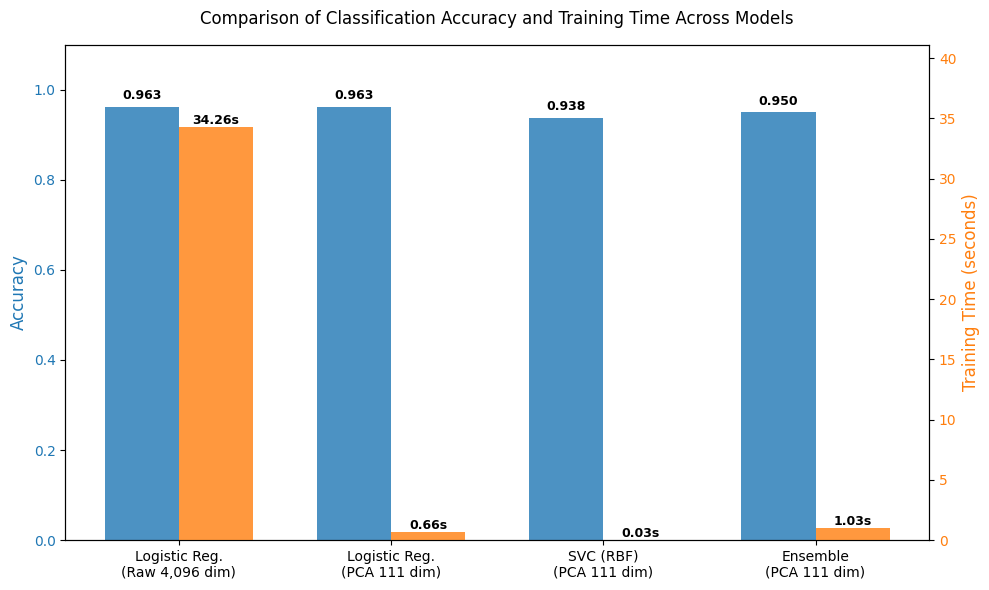

In [ ]:
# Model results gathered from our experiments
models = [
    'Logistic Reg.\n(Raw 4,096 dim)',
    f'Logistic Reg.\n(PCA {n_pca} dim)',
    f'SVC (RBF)\n(PCA {n_pca} dim)',
    f'Ensemble\n(PCA {n_pca} dim)'
]

accuracies = [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy]
train_times = [raw_time, pca_time, svm_time, ensemble_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Instantiate secondary axis for training time
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(train_times) * 1.2)

# Annotate values on top of each bar
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, f"{yval:.3f}",
             ha="center", va="bottom", fontsize=9, fontweight="bold")
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, yval, f"{yval:.2f}s",
             ha="center", va="bottom", fontsize=9, fontweight="bold")

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()